#### Bar charts for method B (2 pointer)

X-axis: total number of failures f over the whole run. x in [0 to k-1]:

Each bar is labelled with P(F = f), the chance that a run has f failures.

Calculate total expected time by weighting each chart's bars by P(F = f) and summing - is a probability mass function



In [5]:
from functools import lru_cache

import matplotlib.pyplot as plt

from shared import failure_sets, pair_schedules, B_worst_rounds, targets_this_round
from pathlib import Path

Path("images").mkdir(exist_ok=True)

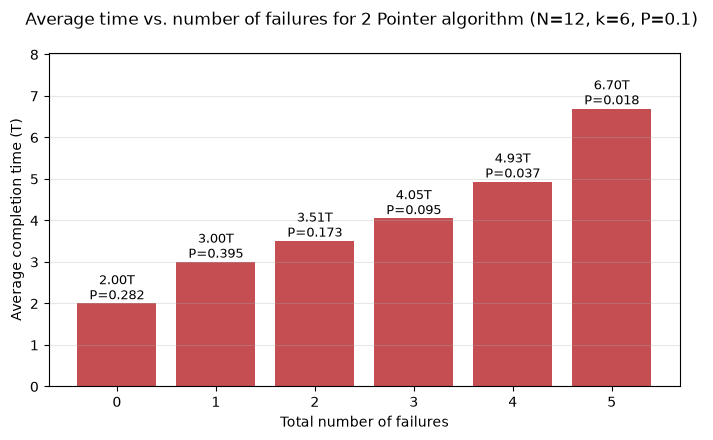

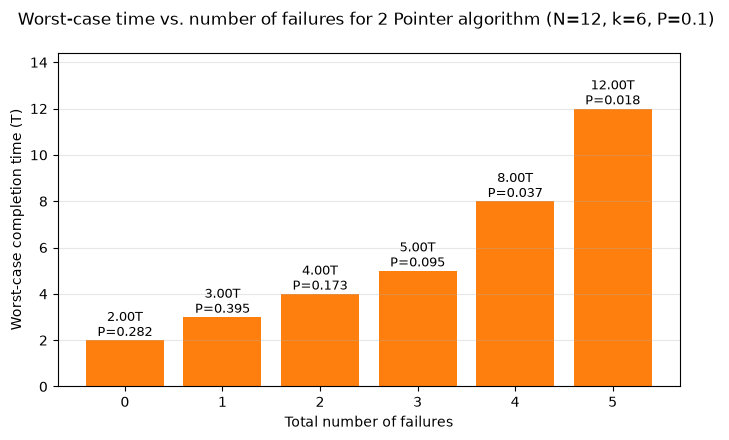

In [6]:
N = 12             # partitions
k = 6              # workers (even)
P = 0.1            # failure probability per worker per round


def B_time_by_failure_count(schedules, N, P, count_final_round=False):
    """For each total failure count f: (P(F = f), E[T | F = f]).
    Failures in the round where the job finishes have no effect, so by default they are not counted.

    >>> d = B_time_by_failure_count(pair_schedules(5, 2), 5, 0.1)
    >>> [(f, round(p, 4), round(t, 4)) for f, (p, t) in sorted(d.items())]
    [(0, 0.6561, 3.0), (1, 0.3439, 4.5525)]
    """
    k = len(schedules)
    all_done = (1 << N) - 1

    @lru_cache(maxsize=None)
    def G(done, alive):
        # {f: (probability of f more failures, sum of probability x remaining rounds)}
        if done == all_done:
            return {0: (1.0, 0.0)}
        live = [w for w in range(k) if alive >> w & 1]
        targets = targets_this_round(schedules, done, live)
        result = {}
        for failed, p in failure_sets(len(live), P):          # every outcome of this round
            new_done, new_alive = done, alive
            for i, w in enumerate(live):
                if failed[i]:
                    new_alive &= ~(1 << w)
                else:
                    new_done |= 1 << (targets[i] - 1)
            job_ends = (new_done == all_done)                      # this is the final round
            counted = 0 if (job_ends and not count_final_round) else sum(failed)
            for more, (q, m) in G(new_done, new_alive).items():
                f = counted + more
                prob, mass = result.get(f, (0.0, 0.0))
                # this round adds 1 to the time of every run that passes through it
                result[f] = (prob + p * q, mass + p * (m + q))
        return result

    dist = G(0, (1 << k) - 1)
    return {f: (p, m / p) for f, (p, m) in dist.items() if p > 0}


def bar_chart(f_values, heights, probs, ylabel, title, filename, color):
    plt.figure(figsize=(7, 4.5))
    bars = plt.bar(f_values, heights, color=color)
    for bar, h, p in zip(bars, heights, probs):
        plt.text(bar.get_x() + bar.get_width() / 2, h, f"{h:.2f}T\nP={p:.3f}",
                 ha="center", va="bottom", fontsize=9)
    plt.xticks(f_values)
    plt.ylim(0, max(heights) * 1.2)               # room for the labels, whatever N is
    plt.xlabel("Total number of failures")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(Path("images") /filename, dpi=150)
    plt.show()


if __name__ == "__main__":
    S = pair_schedules(N, k)
    by_f = B_time_by_failure_count(S, N, P)
    f_values = list(range(k))                                  # 0 .. k-1
    probs = [by_f.get(f, (0.0, 0.0))[0] for f in f_values]
    avg_times = [by_f.get(f, (0.0, 0.0))[1] for f in f_values]
    worst_times = [B_worst_rounds(S, N, f) for f in f_values]

    expected = sum(p * t for p, t in zip(probs, avg_times))
    expected_worst = sum(p * w for p, w in zip(probs, worst_times))

    bar_chart(f_values, avg_times, probs,
              ylabel="Average completion time (T)",
              title=f"Average time vs. number of failures for 2 Pointer algorithm (N={N}, k={k}, P={P}) \n"
                    #f"overall expected time = {expected:.3f} rounds"
                    ,
              filename="d_average_time_by_failures.png", color="#C44E52")

    bar_chart(f_values, worst_times, probs,
              ylabel="Worst-case completion time (T)",
              title=f"Worst-case time vs. number of failures for 2 Pointer algorithm (N={N}, k={k}, P={P}) \n"
                    #f"expected worst case = {expected_worst:.3f} rounds"
                    ,
              filename="d_worst_time_by_failures.png", color="#ff7f0e")

#### Bar charts for method A (lower bound, full monitoring)

Same two charts as for method B, with the same N, k and P, so the charts can be compared.

- Average time for each f: same recursion as A's expected time, over (partitions left r, live workers a), but it also tracks the failure count f.
- Worst case for each f: exhaustive search over how many workers fail in each round and which ones.

In [7]:
import itertools
from shared import round_robin_groups


def finished_partitions(r, a, failed):
    """Partitions method A finishes this round when the workers in `failed` (indices) fail.

    >>> finished_partitions(3, 5, {0, 1})     # groups [2, 2, 1]: both workers of partition 0 fail
    2
    """
    groups = round_robin_groups(r, a)
    partition_of_worker = [g for g, size in enumerate(groups) for _ in range(size)]
    return len({partition_of_worker[i] for i in range(a) if i not in failed})


def A_time_by_failure_count(N, k, P, count_final_round=False):
    """Method A: for each total failure count f, (P(F = f), E[T | F = f]).
    Failures in the round where the job finishes have no effect, so by default they are not counted.

    >>> d = A_time_by_failure_count(5, 2, 0.1)
    >>> [(f, round(p, 4), round(t, 4)) for f, (p, t) in sorted(d.items())]
    [(0, 0.6561, 3.0), (1, 0.3439, 4.5525)]
    """
    @lru_cache(maxsize=None)
    def G(r, a):
        # {f: (probability of f more failures, sum of probability x remaining rounds)}
        if r == 0:
            return {0: (1.0, 0.0)}
        if a == 1:
            return {0: (1.0, float(r))}                 # last worker can't fail: r more rounds
        result = {}
        for failed, p in failure_sets(a, P):            # every outcome of this round
            failed_idx = {i for i in range(a) if failed[i]}
            new_r = r - finished_partitions(r, a, failed_idx)
            job_ends = (new_r == 0)                     # this is the final round
            counted = 0 if (job_ends and not count_final_round) else len(failed_idx)
            for more, (q, m) in G(new_r, a - len(failed_idx)).items():
                f = counted + more
                prob, mass = result.get(f, (0.0, 0.0))
                # this round adds 1 to the time of every run that passes through it
                result[f] = (prob + p * q, mass + p * (m + q))
        return result

    dist = G(N, k)
    return {f: (p, m / p) for f, (p, m) in dist.items() if p > 0}


def A_worst_rounds(N, k, f):
    """Most rounds A can take with exactly f failures, over every 'which' and 'when'.

    >>> A_worst_rounds(12, 6, 2)
    3
    >>> A_worst_rounds(8, 5, 1)       # worse than ceil(8/4) = 2: the failure comes in round 2
    3
    """
    @lru_cache(maxsize=None)
    def W(r, a, f_left):
        if r == 0:
            return 0
        if a == 1:
            return r                                    # last worker can't fail
        worst_next = 0
        for x in range(min(f_left, a - 1) + 1):         # how many fail this round
            for failed in itertools.combinations(range(a), x):   # which ones
                done = finished_partitions(r, a, set(failed))
                worst_next = max(worst_next, W(r - done, a - x, f_left - x))
        return 1 + worst_next
    return W(N, k, f)

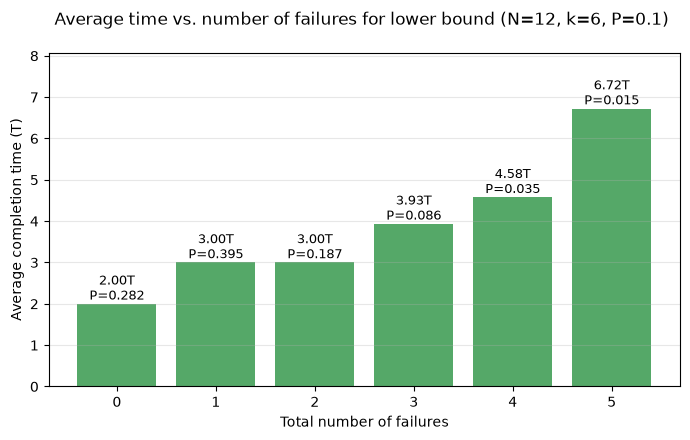

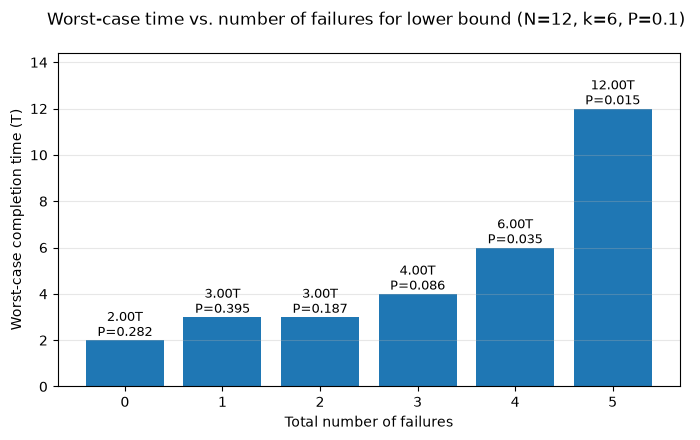

In [8]:
if __name__ == "__main__":
    by_f_A = A_time_by_failure_count(N, k, P)
    f_values = list(range(k))                                  # 0 .. k-1
    probs_A = [by_f_A.get(f, (0.0, 0.0))[0] for f in f_values]
    avg_times_A = [by_f_A.get(f, (0.0, 0.0))[1] for f in f_values]
    worst_times_A = [A_worst_rounds(N, k, f) for f in f_values]

    expected_A = sum(p * t for p, t in zip(probs_A, avg_times_A))
    expected_worst_A = sum(p * w for p, w in zip(probs_A, worst_times_A))

    bar_chart(f_values, avg_times_A, probs_A,
              ylabel="Average completion time (T)",
              title=f"Average time vs. number of failures for lower bound (N={N}, k={k}, P={P}) \n"
                    #f"overall expected time = {expected_A:.3f} rounds"
                    ,
              filename="d_A_average_time_by_failures.png", color="#55A868")

    bar_chart(f_values, worst_times_A, probs_A,
              ylabel="Worst-case completion time (T)",
              title=f"Worst-case time vs. number of failures for lower bound (N={N}, k={k}, P={P}) \n"
                    #f"expected worst case = {expected_worst_A:.3f} rounds"
                    ,
              filename="d_A_worst_time_by_failures.png", color="#1f77b4")